In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist

In [3]:
# Load MNIST dataset
(x_train, _), (x_test, _) =mnist.load_data()

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)


In [4]:
# Convert pixel values from 0-255 to 0-1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Add channel dimension
x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

Training data shape: (60000, 28, 28, 1)
Testing data shape: (10000, 28, 28, 1)


In [5]:
# Define noise factor
noise_factor = 0.5

# Add random Gaussian noise
x_train_noisy = x_train + noise_factor * np.random.normal(
    loc=0.0,
    scale=1.0,
    size=x_train.shape
)

x_test_noisy = x_test + noise_factor * np.random.normal(
    loc=0.0,
    scale=1.0,
    size=x_test.shape
)

# Keep pixel values between 0 and 1
x_train_noisy = np.clip(x_train_noisy, 0.0, 1.0)
x_test_noisy = np.clip(x_test_noisy, 0.0, 1.0)

print("Noise added successfully.")

Noise added successfully.


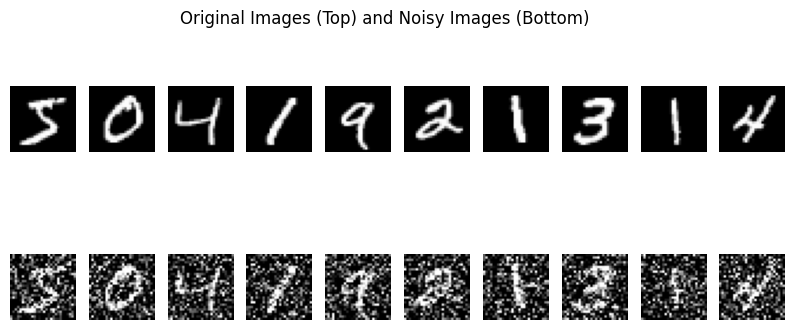

In [6]:
plt.figure(figsize=(10, 4))

for i in range(10):

    # Original image
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_train[i].squeeze(), cmap="gray")
    plt.axis("off")

    # Noisy image
    plt.subplot(2, 10, i + 11)
    plt.imshow(x_train_noisy[i].squeeze(), cmap="gray")
    plt.axis("off")

plt.suptitle("Original Images (Top) and Noisy Images (Bottom)")
plt.show()

In [7]:
# Input layer
input_img = layers.Input(shape=(28, 28, 1))

# Encoder
x = layers.Conv2D(
    32,
    (3, 3),
    activation="relu",
    padding="same"
)(input_img)

x = layers.MaxPooling2D(
    (2, 2),
    padding="same"
)(x)

x = layers.Conv2D(
    16,
    (3, 3),
    activation="relu",
    padding="same"
)(x)

encoded = layers.MaxPooling2D(
    (2, 2),
    padding="same"
)(x)

# Decoder
x = layers.Conv2D(
    16,
    (3, 3),
    activation="relu",
    padding="same"
)(encoded)

x = layers.UpSampling2D((2, 2))(x)

x = layers.Conv2D(
    32,
    (3, 3),
    activation="relu",
    padding="same"
)(x)

x = layers.UpSampling2D((2, 2))(x)

# Output layer
decoded = layers.Conv2D(
    1,
    (3, 3),
    activation="sigmoid",
    padding="same"
)(x)

# Create autoencoder model
autoencoder = models.Model(
    input_img,
    decoded
)

autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 16)       │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,193 (47.63 KB)

 Trainable params: 12,193 (47.63 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
autoencoder.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)

print("Autoencoder compiled successfully.")

Autoencoder compiled successfully.


In [9]:
history = autoencoder.fit(
    x_train_noisy,
    x_train,
    epochs=10,
    batch_size=128,
    shuffle=True,
    validation_data=(x_test_noisy, x_test)
)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 59s 123ms/step - loss: 0.1780 - val_loss: 0.1229
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 61s 131ms/step - loss: 0.1162 - val_loss: 0.1116
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 56s 120ms/step - loss: 0.1114 - val_loss: 0.1088
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 56s 120ms/step - loss: 0.1088 - val_loss: 0.1065
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 56s 119ms/step - loss: 0.1068 - val_loss: 0.1055
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 82s 118ms/step - loss: 0.1051 - val_loss: 0.1034
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 82s 118ms/step - loss: 0.1038 - val_loss: 0.1023
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 55s 117ms/step - loss: 0.1029 - val_loss: 0.1016
Epoch 9/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 55s 118ms/step - loss: 0.1022 - val_loss: 0.1021
Epoch 10/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 82s 117ms/step - loss: 0.1017 - val_loss: 0.1009


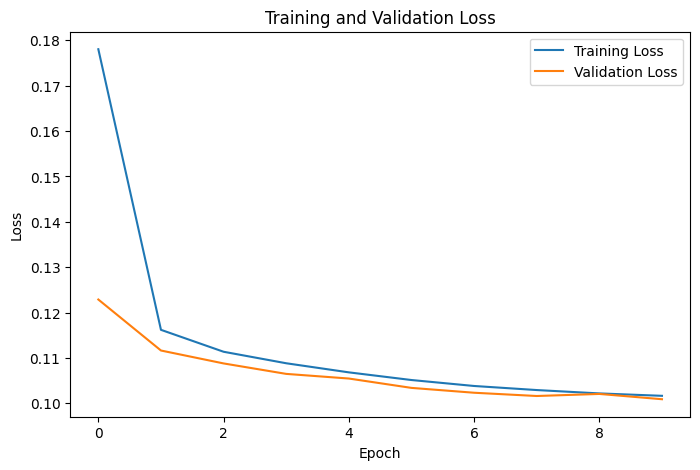

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")

plt.legend()
plt.show()

In [11]:
decoded_imgs = autoencoder.predict(x_test_noisy)

print("Denoising completed.")
print("Output shape:", decoded_imgs.shape)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step
Denoising completed.
Output shape: (10000, 28, 28, 1)


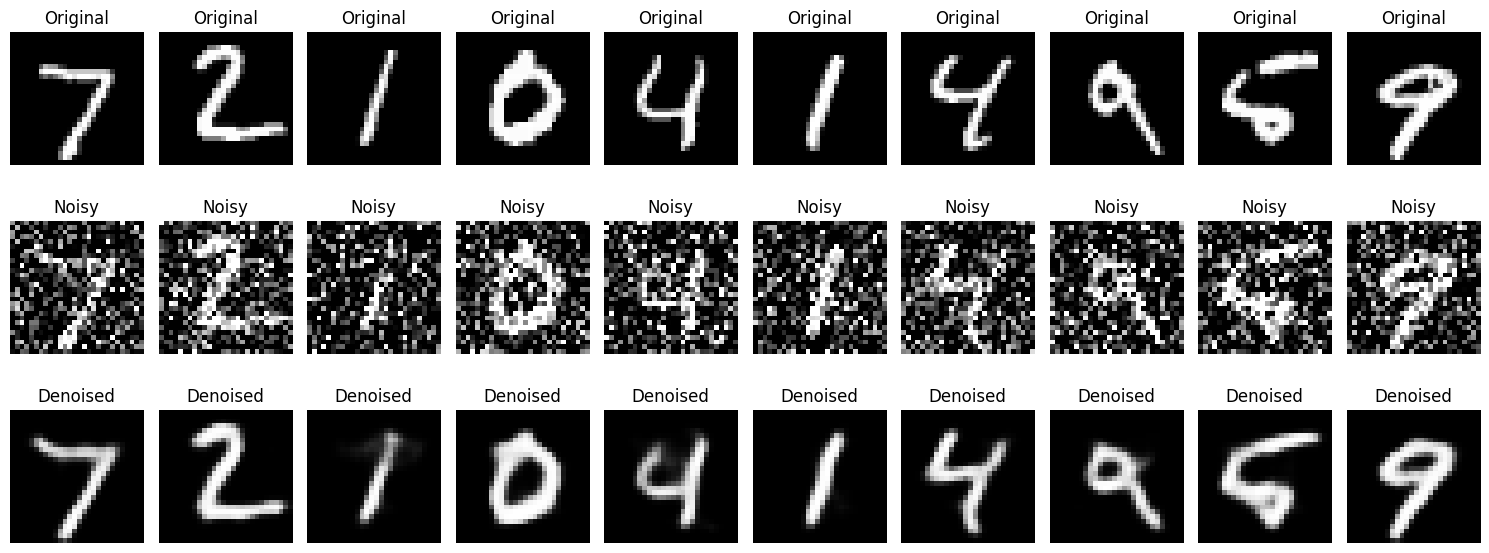

In [12]:
n = 10

plt.figure(figsize=(15, 6))

for i in range(n):

    # Original image
    plt.subplot(3, n, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap="gray")
    plt.title("Original")
    plt.axis("off")

    # Noisy image
    plt.subplot(3, n, i + 1 + n)
    plt.imshow(x_test_noisy[i].squeeze(), cmap="gray")
    plt.title("Noisy")
    plt.axis("off")

    # Denoised image
    plt.subplot(3, n, i + 1 + 2*n)
    plt.imshow(decoded_imgs[i].squeeze(), cmap="gray")
    plt.title("Denoised")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [13]:
mse = np.mean(
    np.square(x_test - decoded_imgs),
    axis=(1, 2, 3)
)

print("Mean Reconstruction Error:", np.mean(mse))
print("Minimum Reconstruction Error:", np.min(mse))
print("Maximum Reconstruction Error:", np.max(mse))

Mean Reconstruction Error: 0.012580057
Minimum Reconstruction Error: 0.001919799
Maximum Reconstruction Error: 0.036040813


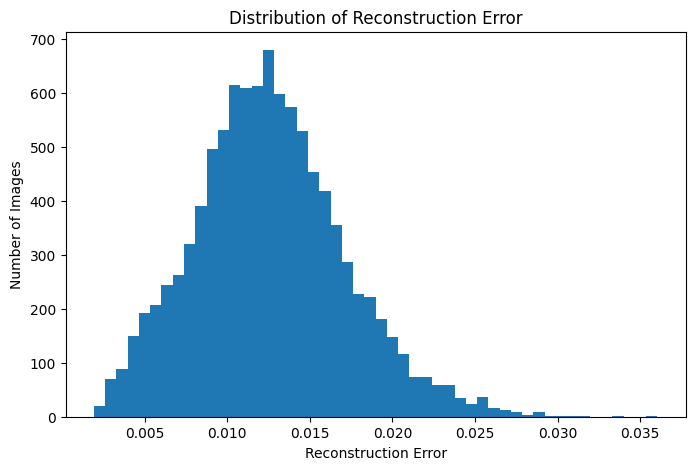

In [14]:
plt.figure(figsize=(8, 5))

plt.hist(mse, bins=50)

plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Images")
plt.title("Distribution of Reconstruction Error")

plt.show()

In [15]:
psnr = tf.image.psnr(
    x_test,
    decoded_imgs,
    max_val=1.0
)

print(
    "Average PSNR:",
    tf.reduce_mean(psnr).numpy(),
    "dB"
)

Average PSNR: 19.323034 dB
